# 01. NIfTI 헤더와 CT-mask 공간 정합 검증

## 검사 이유

CT와 mask의 배열 크기가 같아도 물리 좌표계가 다르면 resampling 과정에서 mask가 이동할 수 있습니다. 따라서 `shape`, voxel spacing, qform/sform, 실제로 선택되는 affine을 함께 비교합니다.

이 단계는 문제를 **검출만** 하며 원본 헤더를 수정하지 않습니다.

In [1]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd

def find_project_root(start=Path.cwd()):
    """VS Code가 프로젝트 폴더/노트북 폴더 중 어디를 cwd로 잡아도 동작하게 합니다."""
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / "project_config.json").is_file() and (candidate / "ctqa_utils.py").is_file():
            return candidate
    raise FileNotFoundError("project_config.json이 있는 CT_Data_Quality_Notebooks 폴더를 VS Code에서 여세요.")

PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT))

from ctqa_utils import *

CONFIG = json.loads((PROJECT_ROOT / "project_config.json").read_text(encoding="utf-8"))
DATA_ROOT = Path(CONFIG["data_root"])
RESULTS = PROJECT_ROOT / "results"
RESULTS.mkdir(exist_ok=True)

print("프로젝트:", PROJECT_ROOT)
print("데이터:", DATA_ROOT)
print("결과 저장:", RESULTS)

프로젝트: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합
데이터: C:\Users\duddl\OneDrive\바탕 화면\CTdata
결과 저장: c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results


In [2]:
pair_path = RESULTS / "00_pair_manifest.csv"
if not pair_path.is_file():
    raise RuntimeError("먼저 00_환경설정_및_파일인벤토리.ipynb를 실행하세요.")
pairs = pd.read_csv(pair_path)
print("검사할 pair:", len(pairs))

검사할 pair: 267


## 1. 모든 NIfTI 헤더 읽기

- `shape`: voxel 배열 차원
- `spacing`: voxel 하나의 물리 크기(mm)
- `qform/sform`: voxel 좌표를 환자 물리 좌표로 바꾸는 규칙
- `effective affine`: 일반 로더가 실제로 선택할 가능성이 높은 변환

In [3]:
rows = []
errors = []
tolerance = float(CONFIG["affine_tolerance"])

for idx, item in pairs.iterrows():
    try:
        image_path, mask_path = Path(item.image_path), Path(item.mask_path)
        ih, mh = read_nifti_header(image_path), read_nifti_header(mask_path)
        ia, ia_source = effective_affine(ih)
        ma, ma_source = effective_affine(mh)
        # spacing 자체는 pixdim 필드끼리 비교하고, affine은 별도 행렬 검사로 분리합니다.
        # oblique/sheared sform의 열 벡터 norm을 spacing으로 다시 해석하면 같은 문제를
        # spacing과 affine에 중복 계상할 수 있습니다.
        image_spacing = tuple(abs(float(x)) for x in ih["pixdim"][1:4])
        mask_spacing = tuple(abs(float(x)) for x in mh["pixdim"][1:4])
        image_affine_spacing = affine_spacing(ia)
        mask_affine_spacing = affine_spacing(ma)
        rows.append({
            "source": item.source,
            "case_id": item.case_id,
            "shape_image": "x".join(map(str, ih["shape"])),
            "shape_mask": "x".join(map(str, mh["shape"])),
            "shape_match": ih["shape"] == mh["shape"],
            "spacing_image": json.dumps(image_spacing),
            "spacing_mask": json.dumps(mask_spacing),
            "affine_spacing_image": json.dumps(image_affine_spacing),
            "affine_spacing_mask": json.dumps(mask_affine_spacing),
            "spacing_max_abs_diff": float(np.max(np.abs(np.asarray(image_spacing) - np.asarray(mask_spacing)))),
            "spacing_match": bool(np.allclose(image_spacing, mask_spacing, atol=tolerance, rtol=0)),
            "image_qform_code": ih["qform_code"],
            "image_sform_code": ih["sform_code"],
            "mask_qform_code": mh["qform_code"],
            "mask_sform_code": mh["sform_code"],
            "header_transform_code_match": bool(
                ih["qform_code"] == mh["qform_code"] and ih["sform_code"] == mh["sform_code"]
            ),
            "image_affine_source": ia_source,
            "mask_affine_source": ma_source,
            "affine_max_abs_diff": affine_max_abs_diff(ia, ma),
            "affine_match": bool(np.allclose(ia, ma, atol=tolerance, rtol=0)),
            "image_det_sign": int(np.sign(np.linalg.det(ia[:3, :3]))),
            "mask_det_sign": int(np.sign(np.linalg.det(ma[:3, :3]))),
            "z_spacing_mm": image_spacing[2],
        })
    except Exception as exc:
        errors.append({"source": item.source, "case_id": item.case_id, "error": repr(exc)})
    if (idx + 1) % 50 == 0:
        print(f"진행: {idx + 1}/{len(pairs)}")

geometry = pd.DataFrame(rows)
geometry.to_csv(RESULTS / "01_geometry_checks.csv", index=False, encoding="utf-8-sig")
pd.DataFrame(errors).to_csv(RESULTS / "01_read_errors.csv", index=False, encoding="utf-8-sig")

summary = geometry.groupby("source").agg(
    readable_cases=("case_id", "count"),
    shape_mismatch=("shape_match", lambda s: int((~s).sum())),
    spacing_mismatch=("spacing_match", lambda s: int((~s).sum())),
    affine_mismatch=("affine_match", lambda s: int((~s).sum())),
    transform_code_mismatch=("header_transform_code_match", lambda s: int((~s).sum())),
    z_spacing_min=("z_spacing_mm", "min"),
    z_spacing_median=("z_spacing_mm", "median"),
    z_spacing_max=("z_spacing_mm", "max"),
).reset_index()
print(summary.to_string(index=False))
print("읽기 오류:", len(errors))

진행: 50/267
진행: 100/267
진행: 150/267
진행: 200/267
진행: 250/267
          source  readable_cases  shape_mismatch  spacing_mismatch  affine_mismatch  transform_code_mismatch  z_spacing_min  z_spacing_median  z_spacing_max
            BHSD             192               0                 0                4                      191            0.5          5.035001       6.518188
PhysioNet_CT_ICH              75               0                 0                0                        0            5.0          5.000000       5.000000
읽기 오류: 0


## 2. 자동 검사와 시각 overlay를 함께 보는 이유

affine 숫자가 다르더라도 voxel 배열 자체는 맞게 저장됐을 수 있습니다. 반대로 자동 검사가 통과해도 좌우 반전이나 한두 slice offset이 남을 수 있습니다. 따라서 대표 사례의 CT-mask overlay를 직접 확인합니다.

BHSD ID_089596a9_ID_ea71b57820 -> c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\01_overlay_BHSD.png


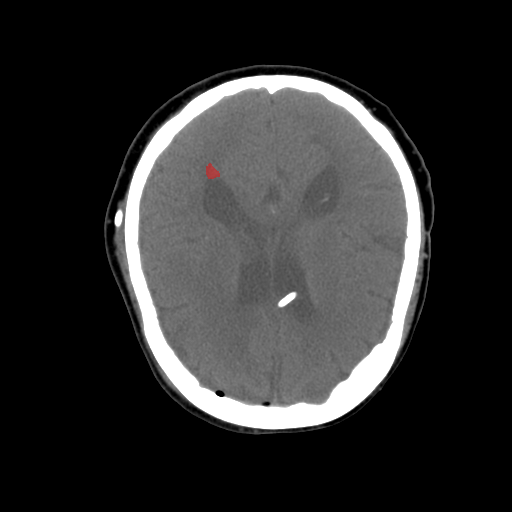

PhysioNet_CT_ICH 049 -> c:\workspace\hodgepodge\hy\데이터품질검증 및 통합\results\01_overlay_PhysioNet_CT_ICH.png


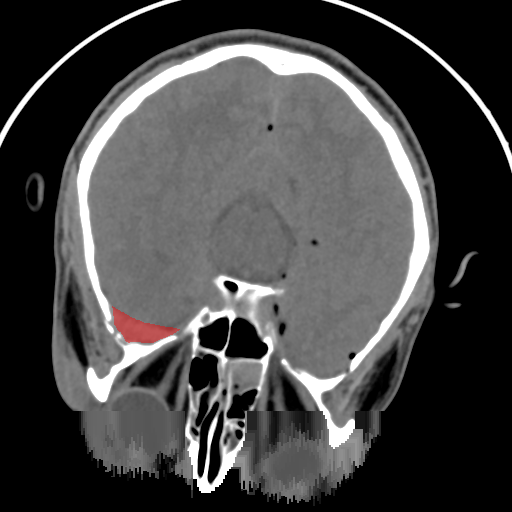

In [4]:
from IPython.display import display, Image as IPImage

overlay_paths = []
for source in ["BHSD", "PhysioNet_CT_ICH"]:
    source_rows = geometry[geometry.source == source]
    candidate_id = (
        source_rows.loc[~source_rows.affine_match, "case_id"].iloc[0]
        if (~source_rows.affine_match).any()
        else source_rows.case_id.iloc[0]
    )
    item = pairs[(pairs.source == source) & (pairs.case_id == candidate_id)].iloc[0]
    ct = read_nifti_data(Path(item.image_path), scaled=True)
    mask = read_nifti_data(Path(item.mask_path), scaled=True)
    out = save_overlay(ct, mask, RESULTS / f"01_overlay_{source}.png")
    overlay_paths.append(out)
    print(source, candidate_id, "->", out)
    display(IPImage(filename=str(out)))

## 3. 단계 판정

- shape·spacing 불일치는 0건이어야 합니다.
- affine 불일치는 자동 수정하지 않고 overlay 전수 검토 후 승인된 보정 규칙을 적용해야 합니다.
- 보정할 때는 mask voxel 배열과 label hash가 변하지 않아야 합니다.

In [5]:
geometry_result = {
    "read_errors": len(errors),
    "shape_mismatch": int((~geometry.shape_match).sum()),
    "spacing_mismatch": int((~geometry.spacing_match).sum()),
    "affine_mismatch": int((~geometry.affine_match).sum()),
    "transform_code_mismatch": int((~geometry.header_transform_code_match).sum()),
    "affine_mismatch_by_source": {
        source: int((~group.affine_match).sum()) for source, group in geometry.groupby("source")
    },
    "transform_code_mismatch_by_source": {
        source: int((~group.header_transform_code_match).sum()) for source, group in geometry.groupby("source")
    },
}
write_json(RESULTS / "01_step_result.json", geometry_result)
print(geometry_result)
print("\n판정: affine 불일치가 0이 아니면 현재 상태에서는 통합 HOLD입니다.")

{'read_errors': 0, 'shape_mismatch': 0, 'spacing_mismatch': 0, 'affine_mismatch': 4, 'transform_code_mismatch': 191, 'affine_mismatch_by_source': {'BHSD': 4, 'PhysioNet_CT_ICH': 0}, 'transform_code_mismatch_by_source': {'BHSD': 191, 'PhysioNet_CT_ICH': 0}}

판정: affine 불일치가 0이 아니면 현재 상태에서는 통합 HOLD입니다.
